# Module 4: Continuous Time, Itô Calculus and Black-Scholes, Tested on Real Data

*By Héctor Ornelas*

Markets do not move in daily steps, so this module lets the time step shrink to zero. The random walk
becomes Brownian motion, ordinary calculus stops working, and a new rule, Itô's lemma, takes its place.
With it come the classic continuous-time models: geometric Brownian motion for prices,
Ornstein-Uhlenbeck and Cox-Ingersoll-Ross for interest rates, and Black-Scholes for options. As
before, I take the eleven topics of the course in the same order and test each one with real data.

The rules are the same as in Module 1: same topics as the course, real data from a Mexican point of
view, and every formula written by hand. This module uses two new series, both downloaded by
`download_data.py`: the VIX, which is the volatility that the market prices into S&P 500 options, and
interest rates from FRED, the Mexican 3-month interbank rate and the US 3-month T-bill.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf, exp, log, sqrt

# fix the seed so every run gives exactly the same numbers
np.random.seed(37)

# one common style for all the plots: size, a light grid, and font size
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

def Phi(x):
    # standard normal CDF, written with the error function
    return 0.5 * (1 + erf(x / sqrt(2)))

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
rates = pd.read_csv("data/rates.csv", index_col=0, parse_dates=True)

ipc = prices["IPC"].dropna()
r = np.log(ipc).diff().dropna()

## 1. From random walk to Brownian motion: the $\sqrt{\Delta t}$ scaling

If a fixed period is split into $n$ steps of size $\lambda z$, the variance of the total is
$n\lambda^2$. For this to stay finite when the steps get smaller, the step size must be proportional to
$\sqrt{\Delta t}$, and that choice defines **Brownian motion**. In practice, it means that the standard
deviation of a step divided by $\sqrt{\Delta t}$ should be the same for any step size.

**Exercise 1. Steps of different sizes.** I measure the IPC with steps of a day, a week, a month and a
quarter, and I divide the standard deviation of each step by $\sqrt{\text{days}}$ and by
$\text{days}$.

In [2]:
logp = np.log(ipc.values)
print(f"{'step':<9}{'days':>5}{'std of step':>13}{'std / sqrt(days)':>18}{'std / days':>12}")
for name, h in [("1 day", 1), ("1 week", 5), ("1 month", 21), ("1 quarter", 63)]:
    step = logp[h::h] - logp[:-h:h]                 # non-overlapping steps of h days
    sd = step.std()
    print(f"{name:<9}{h:>5}{sd:>13.4f}{sd / sqrt(h):>18.4f}{sd / h:>12.4f}")

step      days  std of step  std / sqrt(days)  std / days
1 day        1       0.0116            0.0116      0.0116
1 week       5       0.0263            0.0118      0.0053
1 month     21       0.0532            0.0116      0.0025
1 quarter   63       0.0809            0.0102      0.0013


Divided by $\sqrt{\text{days}}$, the numbers stay almost constant, between 0.0102 and 0.0118, while
divided by days they fall from 0.0116 to 0.0013. So the real IPC follows the $\sqrt{\Delta t}$ scaling
of Brownian motion, and this is why a continuous-time model with this scaling can describe it. The
quarterly value is a bit lower, but the difference is small, and Module 2 showed that for the IPC a
difference of this size cannot be separated from noise.

## 2. Universality: the shape of each step does not matter

Brownian motion does not depend on the distribution of the small steps. As long as they are
independent with a finite variance, the sum becomes normal. This is the Central Limit Theorem of
Module 1, applied to paths.

**Exercise 2. A year built from real days.** I build 20,000 years by drawing 252 real daily returns of
the IPC at random, and I compare the distribution of the yearly sum with a normal.

excess kurtosis of one real day  : 5.99
excess kurtosis of a 252-day sum : -0.01   (normal = 0)


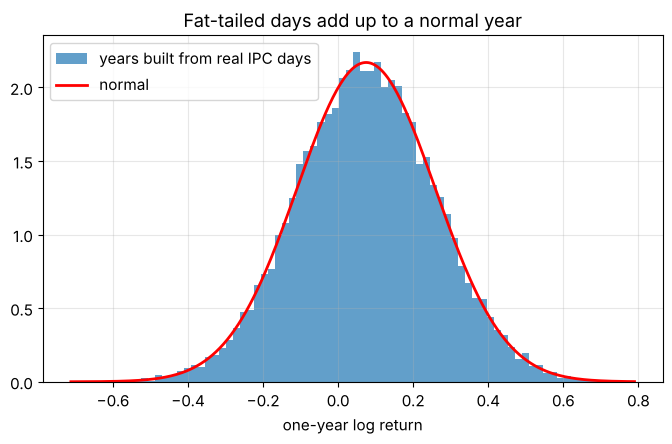

In [3]:
# one year built from 252 real IPC days drawn at random, against a normal with the same mean and std
n_years = 20_000
idx = np.random.randint(0, len(r), size=(n_years, 252))
year_sum = r.values[idx].sum(axis=1)

def ex_kurt(x):
    c = x - x.mean()
    return np.mean(c**4) / x.std()**4 - 3

print(f"excess kurtosis of one real day  : {ex_kurt(r.values):.2f}")
print(f"excess kurtosis of a 252-day sum : {ex_kurt(year_sum):.2f}   (normal = 0)")

grid = np.linspace(year_sum.min(), year_sum.max(), 300)
m, s = year_sum.mean(), year_sum.std()
plt.hist(year_sum, bins=80, density=True, alpha=0.7, label="years built from real IPC days")
plt.plot(grid, np.exp(-(grid - m)**2 / (2 * s**2)) / (s * sqrt(2 * np.pi)), color="red", lw=2, label="normal")
plt.title("Fat-tailed days add up to a normal year")
plt.xlabel("one-year log return"); plt.legend(); plt.show()

One real day has an excess kurtosis of 5.99, which is very far from normal, and the sum of 252 of them
has $-0.01$, which is normal. So the fat tails of the daily returns disappear when the days are
independent. This is an important detail, because in the real history the yearly returns are not this
clean: Module 1 showed that the days are not independent and that bad days come together. The model
gives a normal year only because the random drawing removes those clusters.

## 3. Brownian paths are continuous but nowhere differentiable

If a path had a slope, then $|\Delta S|/\Delta t$ would settle to a number when $\Delta t$ gets
small. For Brownian motion, $|\Delta S|$ is of size $\sqrt{\Delta t}$, so the "slope" is of size
$1/\sqrt{\Delta t}$ and it grows without limit.

**Exercise 3. The slope of the IPC.** I compute the average size of the change in log price divided by
the length of the step, for steps from a quarter to a day, and I also multiply it by
$\sqrt{\Delta t}$.

In [4]:
# average size of the "slope" |change in log price| / (change in time), measured with smaller and smaller steps
print(f"{'step':<10}{'avg |slope| per year':>22}{'x sqrt(step)':>14}")
for name, h in [("1 quarter", 63), ("1 month", 21), ("1 week", 5), ("1 day", 1)]:
    step = logp[h::h] - logp[:-h:h]
    dt = h / 252
    slope = np.mean(np.abs(step)) / dt
    print(f"{name:<10}{slope:>22.2f}{slope * sqrt(dt):>14.3f}")

step        avg |slope| per year  x sqrt(step)
1 quarter                   0.26         0.130
1 month                     0.47         0.135
1 week                      0.96         0.135
1 day                       2.07         0.131


The "slope" of the IPC goes from 0.26 per year with quarterly steps to 2.07 with daily steps, and it
would keep growing with smaller steps. But multiplied by $\sqrt{\Delta t}$ it stays between 0.130 and
0.135. So the IPC has no speed: the more closely I look, the faster it seems to move. This is why
ordinary calculus, which needs derivatives, cannot be used for prices.

## 4. Quadratic variation: the identity $dB^2 = dt$

For a Brownian motion, the sum of the **squared** changes over a period converges to the length of the
period (times $\sigma^2$), while the sum of the **absolute** changes grows without limit. This is
written as $dB^2 = dt$, and it is the reason for the extra term in Itô's lemma.

**Exercise 4. Realized variance of the IPC.** For each year, I add the squared returns and the absolute
returns, measured with daily, weekly and monthly data.

averages over all years:
  sum of squares (QV):  daily 0.0338   weekly 0.0348   monthly 0.0310
  sum of |moves|  (TV):  daily 2.05     weekly 0.93     monthly 0.42


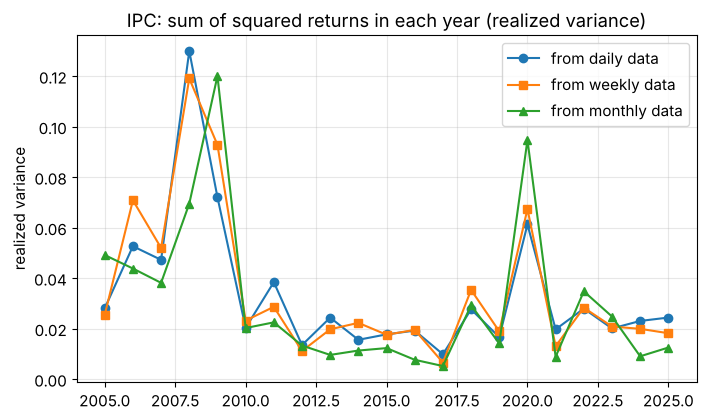

In [5]:
# for each year: sum of squared returns (quadratic variation) and sum of absolute returns (total variation)
rows = []
for y, g in ipc.groupby(ipc.index.year):
    if len(g) < 240:
        continue
    lp = np.log(g.values)
    row = [y]
    for h in [1, 5, 21]:
        st = lp[h::h] - lp[:-h:h]
        row += [np.sum(st**2), np.sum(np.abs(st))]
    rows.append(row)
qv = pd.DataFrame(rows, columns=["year", "QV daily", "TV daily", "QV weekly", "TV weekly", "QV monthly", "TV monthly"]).set_index("year")

print("averages over all years:")
print(f"  sum of squares (QV):  daily {qv['QV daily'].mean():.4f}   weekly {qv['QV weekly'].mean():.4f}   monthly {qv['QV monthly'].mean():.4f}")
print(f"  sum of |moves|  (TV):  daily {qv['TV daily'].mean():.2f}     weekly {qv['TV weekly'].mean():.2f}     monthly {qv['TV monthly'].mean():.2f}")

plt.plot(qv.index, qv["QV daily"], "o-", label="from daily data")
plt.plot(qv.index, qv["QV weekly"], "s-", label="from weekly data")
plt.plot(qv.index, qv["QV monthly"], "^-", label="from monthly data")
plt.title("IPC: sum of squared returns in each year (realized variance)")
plt.ylabel("realized variance"); plt.legend(); plt.show()

The sum of squares is almost the same with any frequency: 0.0338 with daily data, 0.0348 with weekly
and 0.0310 with monthly, and the plot shows that this is true year by year. The sum of absolute moves
does not behave like that: 0.42 with monthly data, 0.93 with weekly and 2.05 with daily. This sum of
squares has a name in practice, **realized variance**, and it is how risk systems measure the
variance of a day or a month from high-frequency data. The fact that it does not depend on the
frequency is quadratic variation working in real data.

## 5. Itô's lemma: the chain rule with an extra term

Because $dB^2 = dt$, the chain rule needs a second-order term. For $f(S) = \ln S$ with
$dS = \mu S\,dt + \sigma S\,dB$, Itô's lemma gives

$$d\ln S = \left(\mu - \tfrac12\sigma^2\right)dt + \sigma\,dB,$$

so the growth of the log price is the average return minus $\sigma^2/2$. The same rule explains
leveraged funds that rebalance every day: with leverage $L$, the growth rate is
$L\mu - \tfrac12 L^2\sigma^2$, so the risk term grows with the square of the leverage.

**Exercise 5. Itô in real data.** First I check that the mean log return equals the mean simple return
minus $\sigma^2/2$ for five series. Then I build the SPY with 1x, 2x and 3x leverage rebalanced every
day, using the real daily returns of the SPY, and compare its growth with the formula.

In [6]:
# Ito: mean log return = mean simple return - sigma^2 / 2
print(f"{'series':<8}{'mean simple':>13}{'- sigma^2/2':>13}{'= Ito says':>12}{'mean log':>11}")
for c in ["IPC", "SPY", "EEM", "GLD", "TLT"]:
    p = prices[c].dropna()
    R = p.pct_change().dropna()
    lr = np.log(p).diff().dropna()
    a, half = R.mean() * 252, R.var() * 252 / 2
    print(f"{c:<8}{a:>13.2%}{half:>13.2%}{a - half:>12.2%}{lr.mean() * 252:>11.2%}")

# leverage rebalanced every day: growth = L * mu - L^2 * sigma^2 / 2
R = prices["SPY"].dropna().pct_change().dropna()
mu, var = R.mean() * 252, R.var() * 252
years = len(R) / 252
print(f"\nSPY with daily-rebalanced leverage, {years:.1f} years:")
print("(built from real SPY returns, without borrowing costs or fees)")
print(f"{'leverage':>9}{'growth/yr':>16}{'Ito says':>10}")
for L in [1, 2, 3]:
    real = np.log(1 + L * R).sum() / years
    print(f"{L:>9}x{real:>15.2%}{L * mu - L**2 * var / 2:>10.2%}")

series    mean simple  - sigma^2/2  = Ito says   mean log
IPC             9.24%        1.70%       7.54%      7.54%
SPY            12.14%        1.78%      10.36%     10.36%
EEM            10.66%        3.81%       6.85%      6.86%
GLD            11.65%        1.67%       9.98%      9.97%
TLT             3.79%        1.06%       2.73%      2.73%

SPY with daily-rebalanced leverage, 21.7 years:
(built from real SPY returns, without borrowing costs or fees)
 leverage       growth/yr  Ito says
        1x         10.36%    10.36%
        2x         17.13%    17.16%
        3x         20.24%    20.40%


The formula works for the five series, with a difference of 0.01 points at most, for example 9.24%
minus 1.70% gives 7.54% for the IPC, exactly its mean log return. The leverage result is the practical one. Doubling the
leverage does not double the growth: 2x gave 17.13% per year instead of $2 \times 10.36\%$, and 3x gave
only 20.24%, very close to what Itô predicts (17.16% and 20.40%). This is why a 3x leveraged fund can
lose money over time even when the index goes up, if the volatility is high enough. These leveraged
versions are theoretical, since they do not pay for borrowing or fees. A real 3x fund pays both, so it
would have grown even less than 20.24%.

## 6. Arithmetic Brownian motion and Bachelier's problem

The first model of prices, by Bachelier in 1900, was an **arithmetic** Brownian motion,
$dS = \mu\,dt + \sigma\,dB$, where the price changes by a fixed amount of points and not by a
percentage. A simple test is to check if the size of the daily changes in points depends on the price
level.

**Exercise 6. Points or percentages?** For each year I compare the average level of the IPC with the
standard deviation of its daily changes in points and in percent.

In [7]:
# if the IPC followed an arithmetic Brownian motion, the daily change in points would have the same size at any level
pts = ipc.diff().dropna()
pct = ipc.pct_change().dropna()
by_year = pd.DataFrame({
    "level": ipc.groupby(ipc.index.year).mean(),
    "std points": pts.groupby(pts.index.year).std(),
    "std %": pct.groupby(pct.index.year).std(),
}).dropna()
print(by_year.iloc[[0, 5, 10, 15, -1]].round({"level": 0, "std points": 0, "std %": 4}).to_string())
print(f"\ncorrelation with the level:  std in points {by_year['level'].corr(by_year['std points']):+.2f}   "
      f"std in % {by_year['level'].corr(by_year['std %']):+.2f}")

# a negative price is impossible for a GBM, but not for an ABM fitted to the same data
mu_pts, sd_pts = pts.mean() * 252, pts.std() * sqrt(252)
S0 = ipc.iloc[0]
print(f"\nABM fitted in points from {S0:,.0f}: P(IPC < 0 after 10 years) = {Phi(-(S0 + mu_pts * 10) / (sd_pts * sqrt(10))):.2%}")

        level  std points   std %
Date                             
2005  14285.0       147.0  0.0105
2010  33283.0       296.0  0.0091
2015  43906.0       371.0  0.0086
2020  39126.0       599.0  0.0156
2026  67298.0       739.0  0.0109

correlation with the level:  std in points +0.65   std in % -0.50

ABM fitted in points from 13,023: P(IPC < 0 after 10 years) = 4.21%


The daily change in points grows with the level, from 147 points in 2005, when the IPC was around
14,000, to 739 in 2026, when it was around 67,000, with a correlation of $+0.65$ with the level. The
change in percent does not grow with the level (correlation $-0.50$). So the IPC moves in percentages,
which is the assumption of geometric Brownian motion, and the arithmetic model would also give a
4.21% chance of a negative IPC after ten years, which is impossible. The arithmetic model is still
used where values can be negative, like spreads or some interest rates.

## 7. Geometric Brownian motion and where $\sigma^2/2$ comes from

With $dS = \mu S\,dt + \sigma S\,dB$, Itô's lemma says that $\ln S_t$ is normal with mean
$\ln S_0 + (\mu - \tfrac12\sigma^2)t$ and variance $\sigma^2 t$. So the median path grows at
$\mu - \tfrac12\sigma^2$ and the mean path grows at $\mu$: the same gap from Module 2.

**Exercise 7. The IPC inside its own GBM.** I fit a GBM to the IPC since 2005 and draw the median, the
mean and the 90% band, and I count how many days the real IPC stayed inside the band.

share of days inside the 90% GBM band: 92.2%
final IPC 66,790   GBM median 66,790   GBM mean 96,618


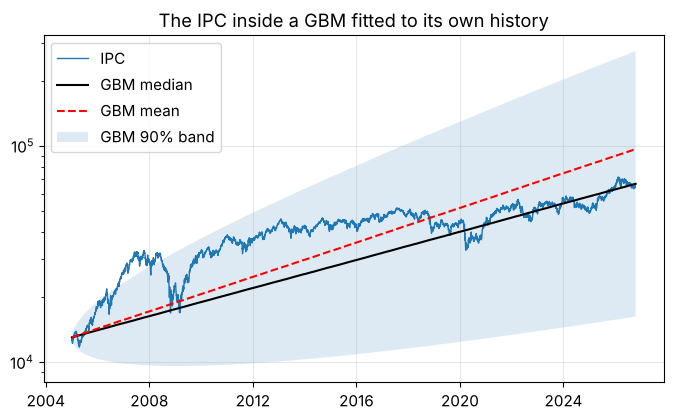

In [8]:
mu_log, sig = r.mean() * 252, r.std() * sqrt(252)
S0 = ipc.iloc[0]
t = np.arange(len(ipc)) / 252

# GBM: log price is normal with mean ln(S0) + (mu - sigma^2/2) t, here written with the mean log return
median = S0 * np.exp(mu_log * t)
lo, hi = S0 * np.exp(mu_log * t - 1.645 * sig * np.sqrt(t)), S0 * np.exp(mu_log * t + 1.645 * sig * np.sqrt(t))
mean = S0 * np.exp((mu_log + sig**2 / 2) * t)

inside = np.mean((ipc.values >= lo) & (ipc.values <= hi))
print(f"share of days inside the 90% GBM band: {inside:.1%}")
print(f"final IPC {ipc.iloc[-1]:,.0f}   GBM median {median[-1]:,.0f}   GBM mean {mean[-1]:,.0f}")

plt.plot(ipc.index, ipc.values, lw=1, label="IPC")
plt.plot(ipc.index, median, color="black", lw=1.5, label="GBM median")
plt.plot(ipc.index, mean, color="red", lw=1.5, ls="--", label="GBM mean")
plt.fill_between(ipc.index, lo, hi, alpha=0.15, label="GBM 90% band")
plt.yscale("log"); plt.title("The IPC inside a GBM fitted to its own history")
plt.legend(); plt.show()

The IPC stayed inside the 90% band 92.2% of the days, so the GBM describes its range well. The median
ends exactly at the final IPC, but this is not a success of the model, it happens because the drift was
estimated with the same data. The useful part of the plot is the gap between the median and the mean:
after 21 years the mean is 96,618 points and the real IPC is 66,790. A projection that uses the mean
of a GBM shows a number that most paths do not reach.

## 8. Ornstein-Uhlenbeck: mean reversion in continuous time

Interest rates do not grow without limit, they move around a level. The **Ornstein-Uhlenbeck** model
describes this:

$$dr = \kappa(\theta - r)\,dt + \sigma\,dB,$$

where $\theta$ is the long-run level and $\kappa$ is the speed of return. Sampled every month, it is the
AR(1) of Module 2, with $b = e^{-\kappa\,\Delta t}$, so I can fit it with the same least squares.

**Exercise 8. The Mexican 3-month rate.** I fit an OU model to the monthly 3-month interbank rate of
Mexico from 2005 to 2026.

260 months, from 3.30% to 11.66%, simple average 6.83%
kappa = 0.069 per year   theta = 5.31%   sigma = 0.75%   half-life = 10.1 years
b = 0.9943 +/- 0.0112  ->  half-life between 3.4 years and infinite (no mean reversion)


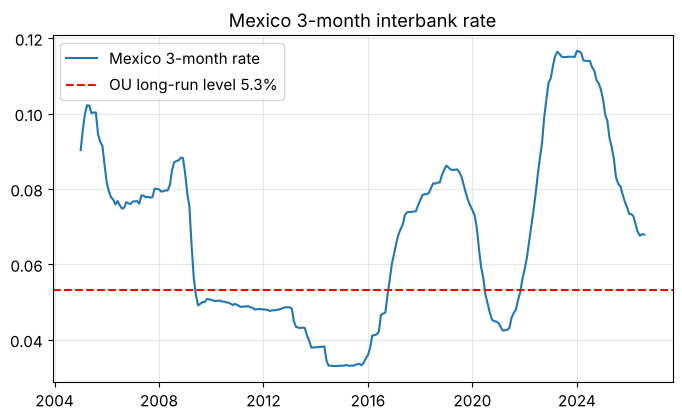

In [9]:
# Mexico 3-month interbank rate, monthly, in decimals
mx = rates["MX3M"].dropna() / 100
dt = 1 / 12

# an OU sampled every month is an AR(1): r_(t+1) = a + b * r_t + e, with b = exp(-kappa * dt)
y, z = mx.values[1:], mx.values[:-1]
b = np.sum((z - z.mean()) * (y - y.mean())) / np.sum((z - z.mean())**2)
a = y.mean() - b * z.mean()
e = y - a - b * z
kappa = -log(b) / dt
theta = a / (1 - b)
sigma_ou = e.std() * sqrt(2 * kappa / (1 - b**2))
print(f"{len(mx)} months, from {mx.min():.2%} to {mx.max():.2%}, simple average {mx.mean():.2%}")
print(f"kappa = {kappa:.3f} per year   theta = {theta:.2%}   sigma = {sigma_ou:.2%}   half-life = {log(2) / kappa:.1f} years")

def half_life_range(y, z, b):
    # approximate range of the half-life with b +/- 2 standard errors (inf = no mean reversion)
    e = y - (y.mean() - b * z.mean()) - b * z
    se = sqrt(np.sum(e**2) / (len(y) - 2) / np.sum((z - z.mean())**2))
    hl = lambda bb: log(2) / (-log(bb) * 12) if bb < 1 else float("inf")
    fmt = lambda h: "infinite (no mean reversion)" if h == float("inf") else f"{h:.1f} years"
    return se, fmt(hl(b - 2 * se)), fmt(hl(b + 2 * se))

se_b, hl_lo, hl_hi = half_life_range(y, z, b)
print(f"b = {b:.4f} +/- {2 * se_b:.4f}  ->  half-life between {hl_lo} and {hl_hi}")

plt.plot(mx.index, mx.values, lw=1.5, label="Mexico 3-month rate")
plt.axhline(theta, color="red", ls="--", label=f"OU long-run level {theta:.1%}")
plt.title("Mexico 3-month interbank rate"); plt.legend(); plt.show()

The Mexican rate moved between 3.30% and 11.66%, in long cycles of easing and tightening by Banxico.
The fitted model has a long-run level of 5.31% and a half-life of 10.1 years, which means that the
rate almost does not return to an average within the sample. This is the same problem as the mean
return in Module 3. With only two or three full cycles in 21 years, the speed of mean reversion is hard
to estimate, and the last line of the output shows how hard. With two standard errors, the half-life
goes from 3.4 years to infinite, which means that the data cannot even rule out that the rate does not
return to any average. The long-run level of 5.31% is also well below the simple average of the period
(6.83%). This range is approximate, because the usual standard error is less reliable when $b$ is this
close to 1, but the conclusion holds: the OU form is reasonable for a rate, and its parameters for Mexico
are very uncertain.

## 9. Cox-Ingersoll-Ross and the Feller condition

The OU model allows negative rates, because its shocks do not depend on the level. The
**Cox-Ingersoll-Ross** model makes the shocks smaller when the rate is low:

$$dr = \kappa(\theta - r)\,dt + \sigma\sqrt{r}\,dB.$$

If $2\kappa\theta \ge \sigma^2$ (the **Feller condition**), the rate never touches zero.

**Exercise 9. The US rate near zero.** The US 3-month rate was close to zero from 2009 to 2015 and
again in 2020 and 2021. I fit the model to monthly data, check the Feller condition, and simulate both
models for 7 years starting from December 2008.

In [10]:
# US 3-month T-bill, end of each month, in decimals
us = rates["US3M"].dropna().resample("ME").last().dropna() / 100
dt = 1 / 12
y, z = us.values[1:], us.values[:-1]
b = np.sum((z - z.mean()) * (y - y.mean())) / np.sum((z - z.mean())**2)
a = y.mean() - b * z.mean()
kappa, theta = -log(b) / dt, a / (1 - b)

# CIR volatility: the shocks scale with sqrt(r), so divide them by sqrt(r) (only months with r > 0.25%)
ok = z > 0.0025
sigma_cir = np.std((y - a - b * z)[ok] / np.sqrt(z[ok])) / sqrt(dt)
sigma_ou = np.std(y - a - b * z) / sqrt(dt)
print(f"US 3-month rate: months below 0.25%: {np.mean(us.values < 0.0025):.0%} of {len(us)}")
print(f"kappa = {kappa:.3f}   theta = {theta:.2%}   sigma (OU) = {sigma_ou:.2%}   sigma (CIR) = {sigma_cir:.3f}")
se_b, hl_lo, hl_hi = half_life_range(y, z, b)
print(f"half-life {log(2) / kappa:.1f} years, between {hl_lo} and {hl_hi}")
print(f"Feller condition 2 kappa theta >= sigma^2:  {2 * kappa * theta:.5f} vs {sigma_cir**2:.5f}  ->  {'holds' if 2 * kappa * theta >= sigma_cir**2 else 'fails'}")

# simulate both models for 7 years from the rate of December 2008
r0 = us["2008-12"].iloc[0]
n_paths, n_steps = 5_000, 7 * 12
ou = np.full(n_paths, r0); cir = np.full(n_paths, r0)
neg_ou = np.zeros(n_paths, bool)
for _ in range(n_steps):
    zz = np.random.normal(size=n_paths)
    ou = ou + kappa * (theta - ou) * dt + sigma_ou * sqrt(dt) * zz
    cir = np.maximum(cir + kappa * (theta - cir) * dt + sigma_cir * np.sqrt(np.maximum(cir, 0) * dt) * zz, 0)
    neg_ou |= ou < 0
print(f"\nstarting at {r0:.2%} in Dec 2008, share of paths that go below zero in 7 years:  OU {neg_ou.mean():.0%}   CIR 0%")

US 3-month rate: months below 0.25%: 42% of 262
kappa = 0.037   theta = 3.80%   sigma (OU) = 0.70%   sigma (CIR) = 0.066
half-life 18.9 years, between 3.5 years and infinite (no mean reversion)
Feller condition 2 kappa theta >= sigma^2:  0.00279 vs 0.00435  ->  fails

starting at 0.11% in Dec 2008, share of paths that go below zero in 7 years:  OU 84%   CIR 0%


The US rate was below 0.25% in 42% of the months, which is a hard case for any model. Starting from
0.11% in December 2008, 84% of the OU paths go below zero in 7 years, while the CIR paths cannot. The
Feller condition fails (0.00279 against 0.00435), so the fitted CIR can touch zero, but it stays at
zero or above, which is closer to what happened. This is the main reason to prefer a model like CIR
for rates close to zero, even if, as with Mexico, its parameters are hard to estimate: the half-life of
the US rate also goes from 3.5 years to infinite.

## 10. Delta hedging: making the risk disappear

Black-Scholes says that an option can be replicated with the stock and cash. If I sell a call and buy
$\Delta = \partial C/\partial S$ shares, rebalancing continuously, the risk of the stock's direction
disappears, and what is left depends only on the difference between the volatility used to price the
option and the volatility that actually happens.

**Exercise 10. Selling and hedging one-month SPY calls.** Every month since 2005 I sell an at-the-money
call on the SPY that expires at the end of the month, priced with Black-Scholes using the VIX as the
volatility and the US 3-month rate. I hedge it every day with the Black-Scholes delta, and I compare
the result with not hedging at all. Results are in percent of the SPY price.

In [11]:
def bs_call(S, K, T, r, sig):
    # Black-Scholes price and delta of a European call, written by hand
    d1 = (log(S / K) + (r + sig**2 / 2) * T) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    return S * Phi(d1) - K * exp(-r * T) * Phi(d2), Phi(d1)

data = pd.concat([prices[["SPY", "VIX"]], rates["US3M"]], axis=1, sort=True).ffill().dropna()
data = data[data.index.isin(prices["SPY"].dropna().index)]
months = data.groupby(data.index.to_period("M"))

rows = []
for per, g in months:
    if len(g) < 18:
        continue
    S, sig, rate = g["SPY"].values, g["VIX"].iloc[0] / 100, g["US3M"].iloc[0] / 100
    n = len(g) - 1
    K = S[0]                                         # at-the-money call, expires at the end of the month
    price, delta = bs_call(S[0], K, n / 252, rate, sig)
    cash = price - delta * S[0]                      # sell the call, buy delta shares
    for i in range(1, n):
        cash *= exp(rate / 252)
        _, new_delta = bs_call(S[i], K, (n - i) / 252, rate, sig)
        cash -= (new_delta - delta) * S[i]
        delta = new_delta
    cash *= exp(rate / 252)
    payoff = max(S[-1] - K, 0)
    hedged = (cash + delta * S[-1] - payoff) / S[0]
    unhedged = (price * exp(rate * n / 252) - payoff) / S[0]
    realized = np.diff(np.log(S)).std() * sqrt(252)
    rows.append([per, hedged, unhedged, S[-1] / S[0] - 1, sig, realized])
res = pd.DataFrame(rows, columns=["month", "hedged", "unhedged", "spy", "implied", "realized"]).set_index("month")

print(f"{len(res)} months of selling a one-month at-the-money SPY call")
print(f"{'':<12}{'mean P&L':>10}{'std':>8}{'months > 0':>12}")
for c in ["unhedged", "hedged"]:
    print(f"{c:<12}{res[c].mean():>10.3%}{res[c].std():>8.3%}{np.mean(res[c] > 0):>12.0%}")

261 months of selling a one-month at-the-money SPY call
              mean P&L     std  months > 0
unhedged        0.127%  2.417%         57%
hedged          0.399%  0.627%         82%


Without the hedge, selling the call earns 0.127% per month on average, but with a standard deviation
of 2.4% and positive results in only 57% of the months, so it is mostly a bet on the direction of the
market. With the daily hedge, the standard deviation falls to 0.63%, almost four times less, and 82% of
the months are positive. The hedge is not perfect because it is done once a day and not continuously,
but most of the risk disappears, as the theory says.

Two simplifications are worth stating. The results do not include transaction costs, and a hedge that
trades every day would pay the spread and commissions many times, so a real result would be lower.
Also, the VIX is the implied volatility of the S&P 500 index, not of the SPY itself, which is very close
but not exactly the same.

## 11. Black-Scholes: where did $\mu$ go?

The Black-Scholes price does not depend on $\mu$, the expected return of the stock. Two investors who
completely disagree on where the market is going should agree on the price of the option, because the
hedge removes the direction. In real data this means that the hedged result should depend on
volatility and not on the direction of the market.

**Exercise 11. Direction against volatility.** With the months from Section 10, I compare how the
hedged and unhedged results relate to the SPY return, and how the hedged result relates to the
difference between the implied volatility (VIX) and the realized volatility of the month.

correlation with the SPY return of the month:  unhedged -0.87   hedged +0.49

implied vol (VIX) at the start of the month: average 19.2%
realized vol during the month             : average 15.0%
months where implied > realized           : 85%
worst hedged month                        : 2020-03 (-2.70%)
correlation of the hedged P&L with implied - realized: +0.85

correlation of the SPY return with implied - realized : +0.68
hedged P&L vs SPY return, after removing the volatility gap: -0.18


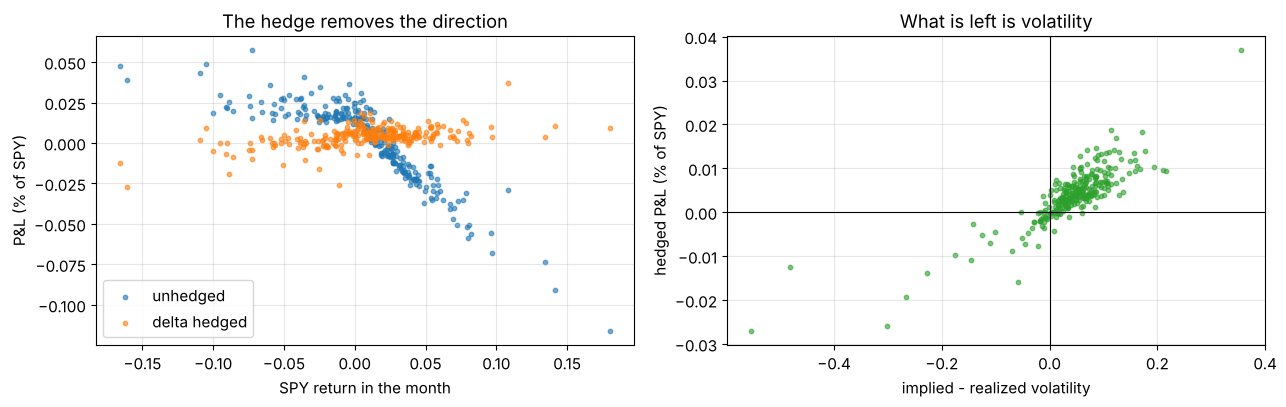

In [12]:
print(f"correlation with the SPY return of the month:  unhedged {res['unhedged'].corr(res['spy']):+.2f}   hedged {res['hedged'].corr(res['spy']):+.2f}")
print(f"\nimplied vol (VIX) at the start of the month: average {res['implied'].mean():.1%}")
print(f"realized vol during the month             : average {res['realized'].mean():.1%}")
print(f"months where implied > realized           : {np.mean(res['implied'] > res['realized']):.0%}")
print(f"worst hedged month                        : {res['hedged'].idxmin()} ({res['hedged'].min():+.2%})")
print(f"correlation of the hedged P&L with implied - realized: {res['hedged'].corr(res['implied'] - res['realized']):+.2f}")

# up months are usually calm months, so part of the link with the SPY goes through volatility
gap = (res["implied"] - res["realized"]).values
X = np.column_stack([np.ones(len(res)), gap])
left = res["hedged"].values - X @ np.linalg.lstsq(X, res["hedged"].values, rcond=None)[0]
print(f"\ncorrelation of the SPY return with implied - realized : {res['spy'].corr(res['implied'] - res['realized']):+.2f}")
print(f"hedged P&L vs SPY return, after removing the volatility gap: {np.corrcoef(left, res['spy'])[0, 1]:+.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(res["spy"], res["unhedged"], s=10, alpha=0.6, label="unhedged")
ax[0].scatter(res["spy"], res["hedged"], s=10, alpha=0.6, label="delta hedged")
ax[0].set_xlabel("SPY return in the month"); ax[0].set_ylabel("P&L (% of SPY)"); ax[0].legend()
ax[0].set_title("The hedge removes the direction")
ax[1].scatter(res["implied"] - res["realized"], res["hedged"], s=10, alpha=0.6, color="tab:green")
ax[1].axhline(0, color="black", lw=0.8); ax[1].axvline(0, color="black", lw=0.8)
ax[1].set_xlabel("implied - realized volatility"); ax[1].set_ylabel("hedged P&L (% of SPY)")
ax[1].set_title("What is left is volatility")
plt.tight_layout(); plt.show()

Without the hedge, the result moves almost one to one against the market, with a correlation of
$-0.87$. With the hedge, the result depends mainly on volatility, with a correlation of $+0.85$ with
the gap between implied and realized volatility. There is still a correlation of $+0.49$ with the SPY,
but it comes through volatility, because months when the market goes up are usually calm months.
After removing the volatility gap, the link with the SPY falls to $-0.18$. So the direction of the
market almost disappears from the hedged result, as Black-Scholes says.

The last numbers explain why selling options earned money in these 21 years. The VIX was on average
19.2%, while the realized volatility was 15.0%, and the VIX was higher in 85% of the months. Option
buyers pay for protection, and that difference is the price. The months when it goes the other way are
few but large, like March 2020, which is the same lesson of fat tails from Module 1.

## Wrapping up Module 4

The continuous-time ideas of this module are visible in real data. The IPC follows the
$\sqrt{\Delta t}$ scaling, it has no slope, and its realized variance is the same with daily, weekly
or monthly data, which is quadratic variation. Itô's lemma explains, to the second decimal, the gap
between the average return and the growth of the money, and it explains why a 3x leveraged SPY grew
far less than three times the SPY.

The models also showed their limits. The IPC moves in percentages and not in points, so the geometric
model is the right one. For interest rates, the OU and CIR forms make sense, but 21 years of Mexican
and US rates are not enough to estimate their speed and long-run level with precision. Finally, delta
hedging with the VIX removed most of the risk of a short call, the direction of the market almost
disappeared from the result, and what was left was the gap between implied and realized volatility,
which is exactly the variable that Black-Scholes says an option depends on.